## Loading Data
* load data from the project directory

In [16]:

import numpy as np
import pandas as pd
from pathlib import Path

PROJECT_ROOT = Path(r'C:\Users\gitsw\Desktop\clear_desktop\TechnicalPortfolio\swetshgit\DL_CUDA_Excercise')
directory = PROJECT_ROOT / 'imputed_envirocar_data'
if not directory.is_dir():
    raise FileNotFoundError(f'Data directory not found: {directory}')


# Initialize an empty list to store dataframes
dfs = []

# Loop through all CSV files in the directory
for csv_file in directory.glob('*.csv'):
        # Load the CSV file into a temporary dataframe
        temp_df = pd.read_csv(csv_file)
        # Append the temporary dataframe to the list
        dfs.append(temp_df)

if not dfs:
    raise FileNotFoundError(f'No CSV files found in {directory}')

print(len(dfs), f"files successfully loaded from {directory}")

envirocar_df = pd.concat(dfs, ignore_index=True)
envirocar_df.reset_index(drop=True,inplace=True)
print(envirocar_df.shape)

856 files successfully loaded from C:\Users\gitsw\Desktop\clear_desktop\TechnicalPortfolio\swetshgit\DL_CUDA_Excercise\imputed_envirocar_data
(327527, 35)


## Imputing missing data
* remove unnecessary columns
* impute missing data

In [17]:
required_columns = [
    'id',
    'CO2(kg/h)',
    'GPS Bearing(deg)',
    'GPS Altitude(m)',
    'Speed(km/h)',
    'Rpm(u/min)',
    'GPS HDOP(precision)',
    'Throttle Position(%)',
    'Intake Temperature(c)',
    'Engine Load(%)',
    'time',
    'Consumption(l/h)',
    'MAF(l/s)',
    'GPS Speed(km/h)',
    'GPS VDOP(precision)',
    'GPS PDOP(precision)',
    'GPS Accuracy(%)'
]
df = envirocar_df.drop(columns=envirocar_df.columns.difference(required_columns))
## Show total number of cells with missing data per each column
df.isnull().sum()

id                            0
MAF(l/s)                 127931
Speed(km/h)                5876
time                          0
Intake Temperature(c)     35506
Rpm(u/min)                 7639
CO2(kg/h)                161326
Consumption(l/h)         161326
Throttle Position(%)     105513
Engine Load(%)           103327
GPS Altitude(m)           16952
GPS Bearing(deg)          16954
GPS Accuracy(%)           16952
GPS Speed(km/h)           16952
GPS HDOP(precision)       29992
GPS VDOP(precision)       29992
GPS PDOP(precision)       29992
dtype: int64

In [18]:
## imputation
df = envirocar_df.drop(columns=envirocar_df.columns.difference(required_columns))
# Define the imputation methods for each column
imputation_methods = {
    'CO2(kg/h)': 'mean',
    'GPS HDOP(precision)': 'ffill',
    'GPS Altitude(m)': 'ffill',
    'GPS Bearing(deg)': 'ffill',
    'Consumption(l/h)': 'mean',
    'Speed(km/h)': 'mean',
    'GPS Speed(km/h)': 'ffill',
    'Rpm(u/min)': 'ffill',
    'Throttle Position(%)':'mean',
    'GPS VDOP(precision)':'ffill',
    'GPS Accuracy(%)': 'ffill',
    'GPS PDOP(precision)': 'ffill',
    'Intake Temperature(c)': 'mean',
    'Engine Load(%)': 'mean',
    'MAF(l/s)': 'mean',
}

# Iterate over each column
for column in df.columns:
    if column in imputation_methods:
        imputation_method = imputation_methods[column]
        if imputation_method == 'mean':
            df[column].fillna(df[column].mean(), inplace=True)
        elif imputation_method == 'ffill':
            df[column].fillna(method='ffill', inplace=True)

#filling in remaining NaNs
df.fillna(method='bfill', inplace=True)
## Check that no missing values are present

print(df.isnull().sum())




id                       0
MAF(l/s)                 0
Speed(km/h)              0
time                     0
Intake Temperature(c)    0
Rpm(u/min)               0
CO2(kg/h)                0
Consumption(l/h)         0
Throttle Position(%)     0
Engine Load(%)           0
GPS Altitude(m)          0
GPS Bearing(deg)         0
GPS Accuracy(%)          0
GPS Speed(km/h)          0
GPS HDOP(precision)      0
GPS VDOP(precision)      0
GPS PDOP(precision)      0
dtype: int64


C:\Users\gitsw\AppData\Local\Temp\ipykernel_20584\117533622.py:27: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[column].fillna(df[column].mean(), inplace=True)
C:\Users\gitsw\AppData\Local\Temp\ipykernel_20584\117533622.py:29: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For e

In [19]:
df

,id,MAF(l/s),Speed(km/h),time,Intake Temperature(c),Rpm(u/min),CO2(kg/h),Consumption(l/h),Throttle Position(%),Engine Load(%),GPS Altitude(m),GPS Bearing(deg),GPS Accuracy(%),GPS Speed(km/h),GPS HDOP(precision),GPS VDOP(precision),GPS PDOP(precision)
0,51c97d05e4b0fe5a04e9e735,0.000000,0.000000,2013-06-08T11:28:20Z,46.190914,653.0,8.169363,3.395984,34.418834,30.836569,109.300003,300.500000,12.0,37.800000,1.3,1.600000,2.100000
1,51c97d05e4b0fe5a04e9e737,0.000374,0.000000,2013-06-08T11:28:26Z,46.190914,653.0,8.169363,3.395984,34.418834,30.836569,109.300003,300.500000,12.0,37.800000,1.3,1.600000,2.100000
2,51c97d05e4b0fe5a04e9e739,0.000419,0.000000,2013-06-08T11:28:34Z,46.190914,653.0,8.169363,3.395984,34.418834,30.836569,109.300003,300.500000,12.0,37.800000,1.3,1.600000,2.100000
3,51c97d05e4b0fe5a04e9e73b,0.000407,0.000000,2013-06-08T11:28:39Z,46.190914,653.0,8.169363,3.395984,34.418834,30.836569,109.300003,300.500000,12.0,37.800000,1.3,1.600000,2.100000
4,51c97d05e4b0fe5a04e9e73d,0.000503,0.000000,2013-06-08T11:28:46Z,46.190914,653.0,8.169363,3.395984,34.418834,30.836569,109.300003,300.500000,12.0,37.800000,1.3,1.600000,2.100000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
327522,661245119828af15e271806b,33.548675,2.949544,2024-04-06T16:11:59Z,47.000000,1559.0,9.919572,4.221094,10.000000,49.803921,100.655887,135.640707,3.0,1.783326,0.9,1.300000,1.600000
327523,661245119828af15e271806c,33.548675,10.500000,2024-04-06T16:12:02Z,47.000000,2315.0,13.630591,5.800252,14.000000,49.803921,100.676066,135.169087,3.0,9.398028,0.9,1.300000,1.600000
327524,661245119828af15e271806d,33.548675,17.000000,2024-04-06T16:12:04Z,46.000000,1727.0,8.390603,3.570469,11.000000,44.313725,100.650442,150.290618,3.0,14.964383,0.9,1.300000,1.600000
327525,661245119828af15e271806e,33.548675,18.000000,2024-04-06T16:12:06Z,46.000000,1943.0,11.476122,4.883456,12.000000,49.803921,100.817448,188.130472,3.0,17.580040,0.9,1.352008,1.652008


## Train Model
* prepare data
* create model
* train data on model
* predict on unseen data

In [20]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense
from sklearn.model_selection import train_test_split


# Select relevant features for training
features = ['GPS HDOP(precision)', 'GPS Altitude(m)', 'GPS Bearing(deg)', 'MAF(l/s)',
            'Consumption(l/h)', 'Speed(km/h)', 'GPS Speed(km/h)', 'Rpm(u/min)',
            'Throttle Position(%)', 'GPS VDOP(precision)', 'GPS PDOP(precision)',
            'GPS Accuracy(%)', 'Intake Temperature(c)', 'Engine Load(%)']
# Normalize the data
scaler = MinMaxScaler()
scaled_data = scaler.fit_transform(df[features])

# Define sequence length for LSTM
sequence_length = 10

# Create sequences for LSTM
def create_sequences(data, sequence_length):
    sequences = []
    targets = []
    for i in range(len(data) - sequence_length):
        sequences.append(data[i:i+sequence_length])
        targets.append(data[i+sequence_length][1])  # Accessing CO2(kg/h) column directly
    return np.array(sequences), np.array(targets)

X, y = create_sequences(scaled_data, sequence_length)

# Split data into training, testing, and validation
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42)

# Build LSTM model
model = Sequential([
    LSTM(50, input_shape=(X_train.shape[1], X_train.shape[2])),
    Dense(1)
])

# Compile the model
model.compile(optimizer='adam', loss='mse')

# Train the model
training = model.fit(X_train, y_train, epochs=20, batch_size=32, validation_data=(X_val, y_val))

# Evaluate the model
loss= model.evaluate(X_test, y_test)
print("Test Loss:", loss)




Epoch 1/20


c:\Users\gitsw\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


6551/6551 ━━━━━━━━━━━━━━━━━━━━ 18s 3ms/step - loss: 1.0025e-04 - val_loss: 3.4867e-05
Epoch 2/20
6551/6551 ━━━━━━━━━━━━━━━━━━━━ 17s 3ms/step - loss: 2.3251e-05 - val_loss: 1.6695e-05
Epoch 3/20
6551/6551 ━━━━━━━━━━━━━━━━━━━━ 16s 2ms/step - loss: 2.0332e-05 - val_loss: 1.8912e-05
Epoch 4/20
6551/6551 ━━━━━━━━━━━━━━━━━━━━ 16s 2ms/step - loss: 1.9307e-05 - val_loss: 2.0277e-05
Epoch 5/20
6551/6551 ━━━━━━━━━━━━━━━━━━━━ 16s 2ms/step - loss: 1.8586e-05 - val_loss: 1.6644e-05
Epoch 6/20
6551/6551 ━━━━━━━━━━━━━━━━━━━━ 16s 2ms/step - loss: 1.8468e-05 - val_loss: 1.7472e-05
Epoch 7/20
6551/6551 ━━━━━━━━━━━━━━━━━━━━ 16s 2ms/step - loss: 1.8178e-05 - val_loss: 2.0587e-05
Epoch 8/20
6551/6551 ━━━━━━━━━━━━━━━━━━━━ 17s 3ms/step - loss: 1.8059e-05 - val_loss: 1.6656e-05
Epoch 9/20
6551/6551 ━━━━━━━━━━━━━━━━━━━━ 19s 3ms/step - loss: 1.7852e-05 - val_loss: 1.6490e-05
Epoch 10/20
6551/6551 ━━━━━━━━━━━━━━━━━━━━ 20s 3ms/step - loss: 1.7769e-05 - val_loss: 1.6416e-05
Epoch 11/20
6551/6551 ━━━━━━━━━━━━━━━━━━

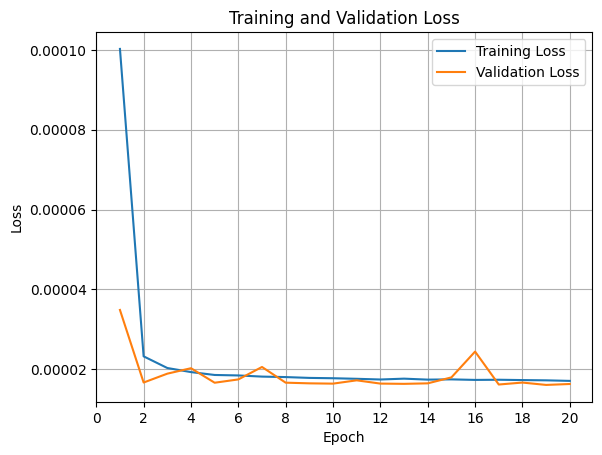

In [21]:
# Plot training loss
import matplotlib.pyplot as plt

epochs = range(1, 21)

plt.plot(epochs, training.history['loss'], label='Training Loss')
plt.plot(epochs, training.history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.xticks(range(0, 21, 2))

plt.legend()
plt.grid(True)
plt.show()

2047/2047 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - loss: 1.5100e-05
2047/2047 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step
Mean Absolute Error (MAE): 0.00170180099845011
Root Mean Squared Error (RMSE): 0.0038858157262698376


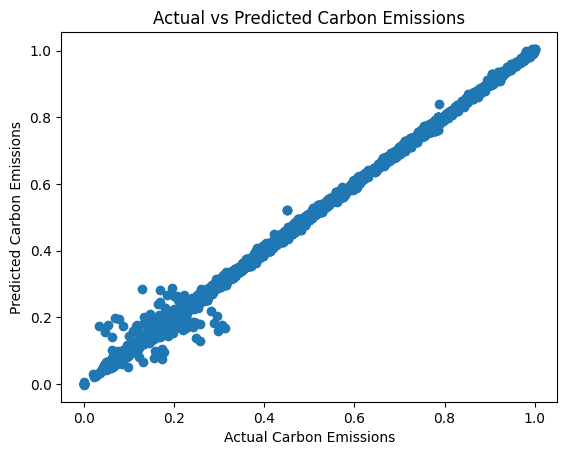

In [22]:
## Evaluating model on unseen data
from sklearn.metrics import mean_absolute_error, mean_squared_error

# # Evaluate the model
loss = model.evaluate(X_test, y_test)

# Calculate additional evaluation metrics
y_pred = model.predict(X_test)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("Mean Absolute Error (MAE):", mae)
print("Root Mean Squared Error (RMSE):", rmse)

import matplotlib.pyplot as plt

plt.scatter(y_test, y_pred)
plt.xlabel('Actual Carbon Emissions')
plt.ylabel('Predicted Carbon Emissions')
plt.title('Actual vs Predicted Carbon Emissions')
plt.show()

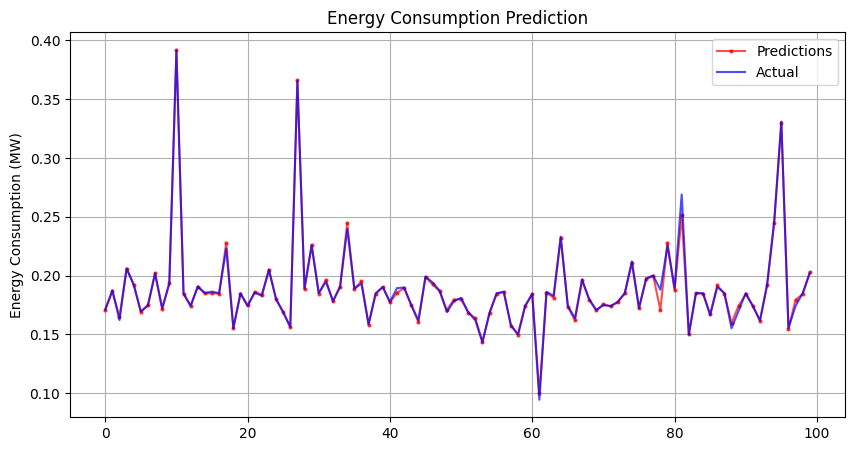

In [23]:
import matplotlib.pyplot as plt

def plot_pred(pred, true):
    pred = pred.squeeze()
    true = true.squeeze()

    plt.figure(figsize=(10, 5))  # Set a larger figure size for better visibility

    # Plot the last 100 predictions with red color, circle markers, and a bit of transparency
    plt.plot(pred[-100:], "-o", color="red", label="Predictions", markersize=2, alpha=0.7)

    # Plot the last 100 actual values with blue color and a bit of transparency
    plt.plot(true[-100:], color="blue", label="Actual", alpha=0.7)

    # Set the y-axis label
    plt.ylabel("Energy Consumption (MW)")

    # Set the title of the plot
    plt.title("Energy Consumption Prediction")

    # Display the legend to differentiate between actual and predicted values
    plt.legend()

    # Add a grid to the plot
    plt.grid(True)

    # Display the plot
    plt.show()

# Example usage (assuming y_test and y_pred are defined and are the correct shape)
plot_pred(y_pred, y_test)



## Train on more than one model
* create several models in array
* save training data to array
* plot training and val loss
* make predictions for each model
* plot predictions for each model

In [24]:
## Train more than one LSTM model.

models = [
    Sequential([
        LSTM(50, input_shape=(X_train.shape[1], X_train.shape[2])),
        Dense(1)
    ]),
    Sequential([
        LSTM(100, input_shape=(X_train.shape[1], X_train.shape[2]), return_sequences=True),
        LSTM(50),
        Dense(1)
    ]),
    Sequential([
        LSTM(64, input_shape=(X_train.shape[1], X_train.shape[2]), return_sequences=True),
        LSTM(64),
        Dense(32),
        Dense(1)
    ])
]

# Compile and train LSTM models
trainings = []
for model in models:
    model.compile(optimizer='adam', loss='mse')
    h = model.fit(X_train, y_train, epochs=20, batch_size=32, validation_data=(X_val, y_val), verbose=1)
    trainings.append(h)


c:\Users\gitsw\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/20
6551/6551 ━━━━━━━━━━━━━━━━━━━━ 26s 4ms/step - loss: 2.3765e-04 - val_loss: 3.2383e-05
Epoch 2/20
6551/6551 ━━━━━━━━━━━━━━━━━━━━ 25s 4ms/step - loss: 2.5071e-05 - val_loss: 1.7877e-05
Epoch 3/20
6551/6551 ━━━━━━━━━━━━━━━━━━━━ 23s 4ms/step - loss: 2.0564e-05 - val_loss: 1.7300e-05
Epoch 4/20
6551/6551 ━━━━━━━━━━━━━━━━━━━━ 27s 4ms/step - loss: 1.9645e-05 - val_loss: 1.7166e-05
Epoch 5/20
6551/6551 ━━━━━━━━━━━━━━━━━━━━ 26s 4ms/step - loss: 1.9115e-05 - val_loss: 1.7014e-05
Epoch 6/20
6551/6551 ━━━━━━━━━━━━━━━━━━━━ 25s 4ms/step - loss: 1.8549e-05 - val_loss: 1.7160e-05
Epoch 7/20
6551/6551 ━━━━━━━━━━━━━━━━━━━━ 24s 4ms/step - loss: 1.8176e-05 - val_loss: 1.6813e-05
Epoch 8/20
6551/6551 ━━━━━━━━━━━━━━━━━━━━ 27s 4ms/step - loss: 1.8104e-05 - val_loss: 1.6062e-05
Epoch 9/20
6551/6551 ━━━━━━━━━━━━━━━━━━━━ 34s 5ms/step - loss: 1.8026e-05 - val_loss: 1.6767e-05
Epoch 10/20
6551/6551 ━━━━━━━━━━━━━━━━━━━━ 28s 4ms/step - loss: 1.7952e-05 - val_loss: 1.7443e-05
Epoch 11/20
6551/6551 ━━━━━━━

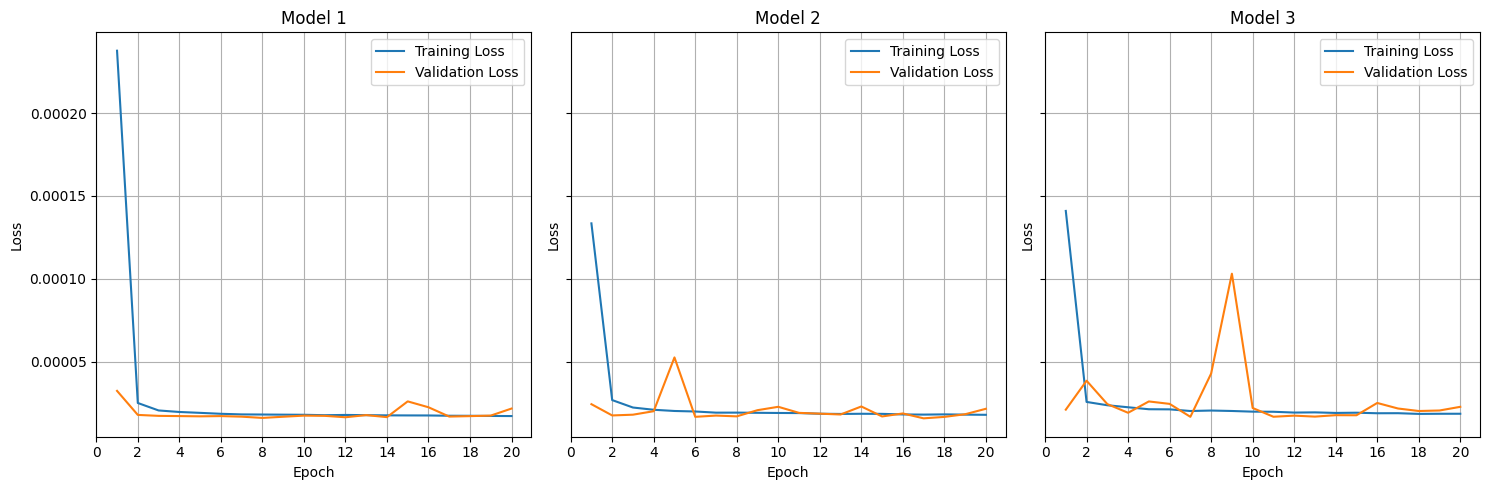

In [25]:
## plot results for models side by side

fig, axs = plt.subplots(1, 3, figsize=(15, 5),sharey=True)

for i,training_data in enumerate(trainings):
    axs[i].plot(epochs, training_data.history['loss'], label='Training Loss')
    axs[i].plot(epochs, training_data.history['val_loss'], label='Validation Loss')
    axs[i].set_title('Model {}'.format(i+1))
    axs[i].set_xlabel('Epoch')
    axs[i].set_ylabel('Loss')
    axs[i].legend()
    axs[i].grid(True)
    axs[i].set_xticks(range(0, 21, 2))

plt.tight_layout()
plt.show()

In [26]:
## make predictions for each model

predictions = []
for model in models:
  y_pred_model = model.predict(X_test)
  predictions.append(y_pred_model)


2047/2047 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step
2047/2047 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step
2047/2047 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step


In [27]:
predictions

[array([[0.1735284 ],
        [0.13225895],
        [0.8015304 ],
        ...,
        [0.17625092],
        [0.18285844],
        [0.20113316]], shape=(65504, 1), dtype=float32),
 array([[0.17318736],
        [0.131264  ],
        [0.807978  ],
        ...,
        [0.17630196],
        [0.18255296],
        [0.20126325]], shape=(65504, 1), dtype=float32),
 array([[0.17840335],
        [0.13624945],
        [0.8029835 ],
        ...,
        [0.18235764],
        [0.1871676 ],
        [0.20515563]], shape=(65504, 1), dtype=float32)]

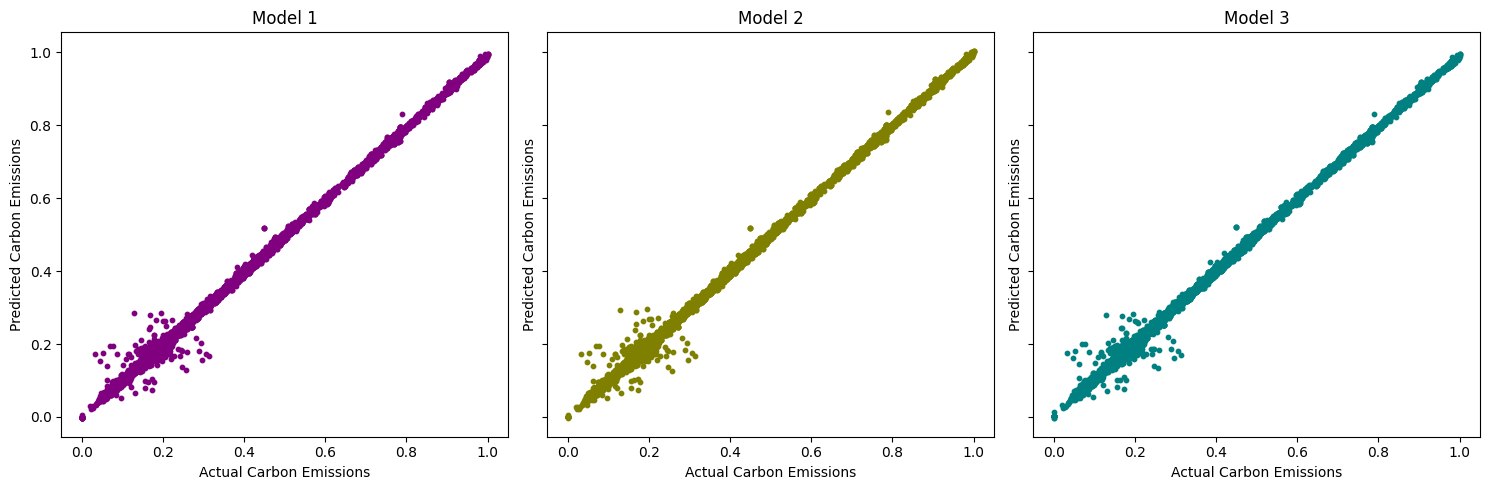

In [28]:
##plotting predictions for each model side by side


colors = ['purple', 'olive', 'teal']

fig, axs = plt.subplots(1, 3, figsize=(15, 5),sharey=True)
for i, y_pred in enumerate(predictions):
    axs[i].scatter(y_test, y_pred, s=10, color=colors[i])
    axs[i].set_title('Model {}'.format(i+1))
    axs[i].set_xlabel("Actual Carbon Emissions")
    axs[i].set_ylabel('Predicted Carbon Emissions')

plt.tight_layout()
plt.show()

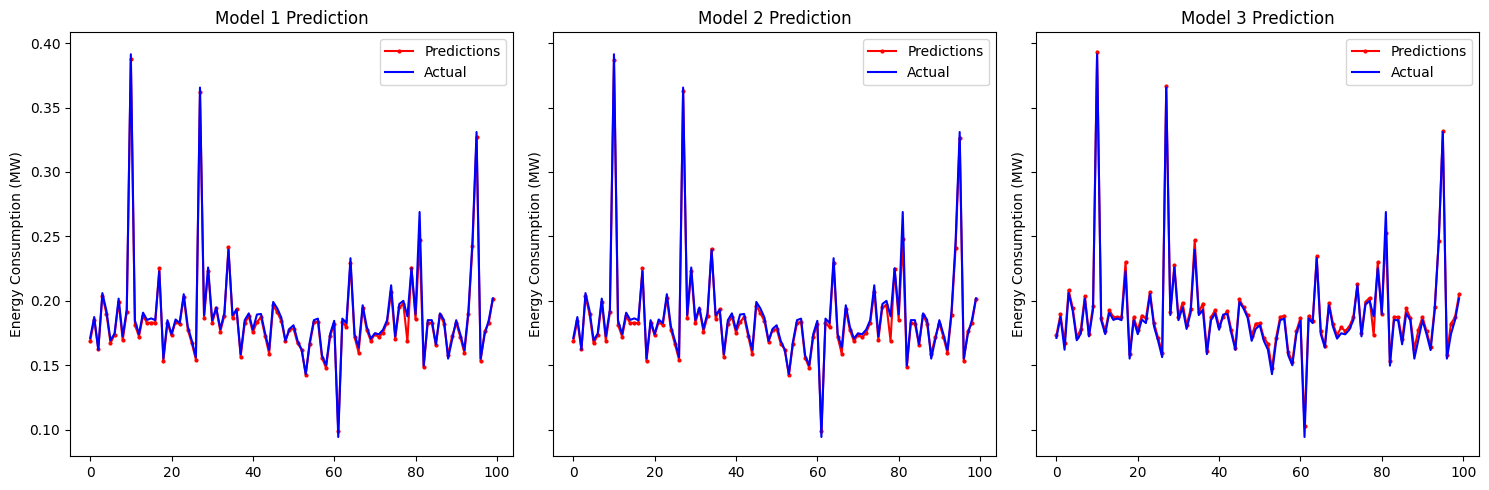

In [29]:
import matplotlib.pyplot as plt

def plot_pred(pred, true, ax, model_num):
    pred = pred.squeeze()[-100:]  # Squeeze to 1D and take last 100 points
    true = true.squeeze()[-100:]  # Squeeze to 1D and take last 100 points

    ax.plot(pred, "-o", color="r", label="Predictions", markersize=2)
    ax.plot(true, color="b", label="Actual")
    ax.set_ylabel("Energy Consumption (MW)")
    ax.set_title(f"Model {model_num} Prediction")
    ax.legend()

fig, axs = plt.subplots(1, 3, figsize=(15, 5), sharey=True)  # Create 3 subplots

# Loop through each model's predictions and plot them on a separate subplot
for i, y_pred in enumerate(predictions):
    plot_pred(y_pred, y_test, axs[i], i+1)

plt.tight_layout()
plt.show()


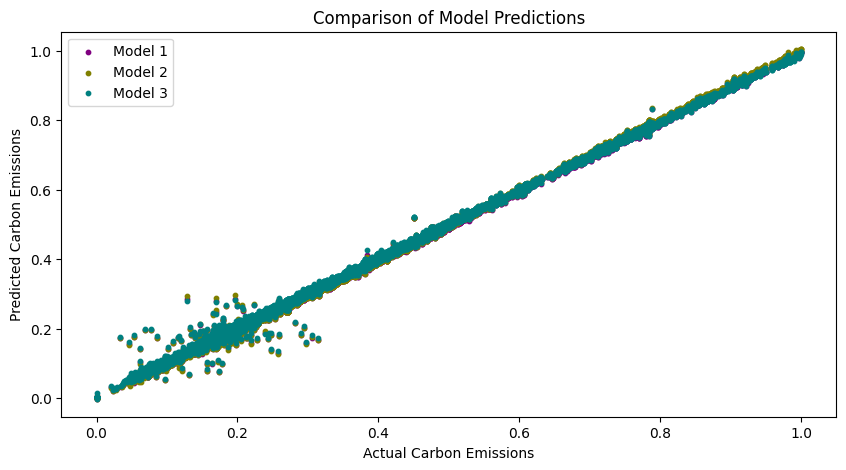

In [30]:
## all in one chart

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 5))

for i, y_pred in enumerate(predictions):
    ax.scatter(y_test, y_pred, s=10, label='Model {}'.format(i+1), color=colors[i])

ax.set_xlabel("Actual Carbon Emissions")
ax.set_ylabel('Predicted Carbon Emissions')
ax.set_title('Comparison of Model Predictions')
ax.legend()

plt.show()